# III. How to: PedestalSubtractedProcess

# From the raw data to estimate and subtract the pedestal

# Introduction

This is an example of how to use `PedestalSubtractedProcess` to estimate the pedestal from a CCD image.  This process is also known as equalization is the process of substracting the pedestal or baseline from an image. The baseline or pedestal is the ADU values for a pixel with zero exposure time (an offset of our readout system).


The CCD images contain a two-dimensional stacked history (projected on the x-y plane) of all ionization produced throughout an exposure, where each image pixel value is proportional to the collected number of charge carriers. The pixel values are in ADU (analog-to-digital units), a 16 bit number (in damic): normally between 0 to 65535, but it depends on the current version of the readout electronics (see invert polarity for instance). The ADU value is related to the number of electrons counted at the sense node by way to the gain k (ADU per electron counted during readout), a constant based on operating condition and is derived from calibration (also known as calibration constant. This constant is then derived from the gain taking into account the energy required to produce an electron-hole pair.

Once the charge is in the serial register, reading the serial register past the length of a row will mean one gets an image that is larger in columns (x-axis) than the size of the sensor (active region). These extra pixels will by definition contain almost no charge sine they will have only been exposed for the amount of time it took to read the entirety of a row. These 0 exposure pixels make up the x-overscan and provide a snapshot of the baseline or pedestal of an image, i.e. the ADU value associated with no charge.

Despite one should expect similar values of pedestal per row and/or per column in a good data taken condition, It is not always like this. `PedestalSubtractionProcess` has the ability to calculate the pedestal per column, per row or in the full region. It is also possible to use the overscan region only, or the full image, masking or not those pixels with pixel charge below a certain value. This is useful when the data taken has long readout times, or show noise pattern along rows and/or columns. 


## Configuration Parameters for `PedestalSubtractedProcess`

### `image` config param

This is the `image` (a data member of the `RawData` instance) to use to estimate the pedestal. See more information about `image` as a data member of `RawData` [here](./howto_Config.html). 

The user can use the raw data image or the compressed one. By defalult the averaged image, i.e. `RawData.image_mean_compressed`.

### `in_overscan` config param

This is a boolean parameter to select only the overscan column region to estimate the pedestal, or on the contrary, to use the full image.

The selected region (full image or only overscan cols region) can also be $\color{green}{\text{masked}}$ (see `n_mad_mask`). This prevent to include pixels from ionizing particles (pixels from tracks will overstimate the pedestal). 


### `method` config param

Name of the method to be used to estimate the pedestal. There are three implemented methods to estimate the pedestal:
 * `mean`: the pedestal will be estimated as the average of a set of pixels from the image
 * `median`: the pedestal will be estimated as the median of a set of pixels from the image
 * `gauss_fit`: the pedestal will be estimated by fitting a gaussian to a set of pixels, being the pedestal the fitted $\mu$
 
In all the methods, a second parameter is given as an estimator of the dispersion: std, mad and $\sigma$ for the `mean`, `median` and `guass_fit`, respectively. 


The set of pixels to use use depends on the `axis` parameter (see below). 

For method `gauss_fit` the set of pixels also depends on `n_sigma_win_fit` (stands for number of sigmas for the spectral window to be used in the fitting process) and `use_mad` (see later on).


### `axis` config param

There are the possible options for this parameter:

 * `row`: the pedestal will be estimated and subtracted row by row
 * `col`: the pedestal will be estimated and subtracted col by col
 * `both`: the pedestal will be estimated row by row, subtacted row by row, then an estimation of col by col will be done, to finally subtract that col by col
 * `full`: the full image will be used to estimate a single value for the pedestal
 

### `n_sigma_win_fit` config param

Method `gauss_fit` fits a gauss to a set of pixels to estimate the pedestal and the disperison (i.e. $\mu$ and $\sigma$ from the fit, respectively). It is extremly important not to include outlier on the fitting process. For that, the algorithm use only those pixel charge within a espectral window:

\begin{equation*}
    q_{row,col} \in [median(q_{row,col}) - n \cdot MAD' , median(q_{row,col}) + n \cdot MAD']
\end{equation*}

where `n` is given by `n_sigma_win_fit`.

The statistic $MAD'$ corresponds to:
* the median absolute deviation, i.e. $MAD$, or
* the MAD as an estimator of the standard deviation, i.e. $1.4826 \cdot MAD$

Being the former less sensitive to outliers (see [wiki](https://en.wikipedia.org/wiki/Median_absolute_deviation) for more detailed information). 

### `n_sigma_to_mask` config param

Pixels from ionizing particles should not be taking into account during pedestal estimation. For that, those pixels with charge above a certain threshold can be masked to prevent it. The process of masking this pixels follows the rule:

those pixels with charge

\begin{equation}
    q_{row,col} > median(q_{row,col}) + n \cdot \text{MAD}
\end{equation}

will not be used to estimate the pedestal. 

`n` is `n_mad_mask`, an integer value (it also accepts floats, if you think it will be better for you case). If negative, no mask at all.

and `MAD` stands for 'median absolute deviation'.


### `use_mad` config param

This parameter set the use of MAD as an estimator of the standard deviation ($False$) or the MAD itself ($True$).


# Index 

In this howto there are two sections:
* Section A: How to from a Python Interpreter
* Section B: How to brom bash

In both cases, we will do the same (fit the dark current), but using two different approaches. The first option allows 
yo to get to know and go deeper into the different sub-modules of `pysimdamicm`, while the second is the use of pysimdamicm as a black box through the `panaSKImg` script.

# A. How to from a Python Interpreter


### Following previous howto 


1. Load all modules needed for this **howto**
2. Define which data to be used
3. Load Configuration file (see [how to I](./I_howto_RawData.ipynb))
4. Create a RawData object (see [how to I](./I_howto_RawData.ipynb))
5. Compress image (see [how to II](./II_howto_CompressSkipperProcess.ipynb))
6. Subtract pedestal (see [how to III](./III_howto_PedestalSubtractedProcess.ipynb))
7. Finally, fit the dark current (this how to)


### 1. Load all modules needed for this howto

In [1]:
%matplotlib inline

# loading damicm module
import pysimdamicm as ccd

# loading other packages
import numpy as np
from matplotlib import pyplot as plt
import ROOT

Welcome to JupyROOT 6.14/06


### 2. Define which data to be used

##### For this example, an image from the Compoton is used. This image has 2000 skips

In [2]:
# variable pointing where my#### data is
path_to_raw_data = "/data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img/"

# pattern file name
img_pattern_file_name = "Image_Am241_Source_55_{}.fits"
# absolute path to the file name
file_name = "{}/{}".format(path_to_raw_data,img_pattern_file_name)

print("\nMy images follows the patter file name:\n {}\n".format(file_name.format("*")))


My images follows the patter file name:
 /data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img//Image_Am241_Source_55_*.fits



### 3. Load configuration file

#### Using the default configuration json file, available in the `pysimdamicm` package


In [3]:
# path where our JSON file is
cfg_file = "{}/json/panaSKImg_configuration.json".format(ccd.__path__[0])

# False to interpret the JSON file as a configuration for data instead of simulations (default one) 
cfg = ccd.utils.config.Config(cfg_file, simulations=False)

### 4. Create a RawData object

#### Load the image using the BuilderRawData function. This will return an object of type RawData

In [4]:
ccd.io.rawdata.__verbose__ = False
rdata = ccd.io.rawdata.BuilderRawData(file_name.format('skip_1'), cfg.configuration['input'])

Correction INFO. Correcting data for Leach bug:
 	 the first two column moved to the end,
 	 move one-row down (only the two last columns).



#### An extra step is needed to read all regions of an image: overscan, prescan and sensor regions

Internally what this function does is the creation of a boolean array for each region. This boolean array with the same size than the full image, should be used against the object `rdata.image_mean_compressed` to select only regions we are insterested in by using `numpy.ma.array`. The object `rdata.image_mean_compressed` is the averaged skip image (see next steps).

In [5]:
rdata.prepare_data()

RawData INFO.
 *********************************************************************** 
 ********* Define mask for sensor and over/pre-scan regions 'Image_Am241_Source_55_skip_1.fits' ********* 
 *********************************************************************** 

 * Active region: 
		rows=0:60
		cols=2:260

 * Overscan  in cols: 
		rows=0:60
		cols=260:275

 * Prescan  in cols: 
		rows=0:60
		cols=0:2

 * NO Overscan  in rows

 * NO Prescan in rows
 ***********************************************************************. 



#### Our data image 

The attribute `image` of `rdata` contains our data image. It is an array of 3 dimensions if the input file corresponds to an skipper image, and a 2D is is the already averaged image.

The dimensions are for:
* number of rows
* number of cols
* number of skips

In [6]:
rdata.image.shape

(60, 275, 2000)

This image has 60 rows, 275 columns and each pixels has been measured 2000 times.

### 5. Compress image

#### Create the averaged image using the process class CompressSkipperProcess

In [7]:
comp = ccd.processes.skipper_analysis.CompressSkipperProcess()
comp.func_to_compress = ['mean']
comp.id_skip_start = 2
comp.execute_process(rdata)

Process <CompressSkipsProcess> INFO. Compressing raw image data using the following statistics: ['mean']
     - used skip range 2:2000
     - image (60, 275, 1998) have been reduced to 60x275



### 6. Subtract pedestal

#### $\color{red}{\text{PedestalSubtractProcess}}$  is the process class to estimate and subract the pedestal


In [8]:
ped = ccd.processes.skipper_analysis.PedestalSubtractionProcess()

### How can we configure this process?

Let's take a look on the configuration parameters available for this process:

In [9]:
ped.info()

<PedestalSubtractionProcess> with sequence id 20.
 List of public data members: 
	 * __sequence_id__ = 20 
	 * __verbose__ = False 
	 * axis = row 
	 * histequ = False 
	 * id_col_end = nan 
	 * id_col_start = nan 
	 * id_row_end = nan 
	 * id_row_start = nan 
	 * id_skip_end = nan 
	 * id_skip_start = nan 
	 * image = mean_compressed 
	 * in_overscan = True 
	 * method = gauss_fit 
	 * n_sigma_to_mask = -1 
	 * n_sigma_win_fit = 10.0 
	 * save_image = False 
	 * save_plots = False 
	 * show_fit = False 
	 * use_mad = True 


This process has a lot of parameters and for that a lot of combinations. 
*$\color{orange}{\text{Be careful when using them,  altough some options are allowd, this does not mean that they all make sense!}}$*

#### Example 1: Pedestal as the mean of the full image

For sure this is never a good option .... 

In [10]:
%matplotlib inline
# set verbose to True to display intermediate plots
ped.__verbose__ = True

In [11]:
# full image
ped.in_overscan = False
ped.axis = "full"
ped.n_sigma_to_mask = -1
# set method
ped.method = 'mean'
# check all set are done
ped.info()

<PedestalSubtractionProcess> with sequence id 20.
 List of public data members: 
	 * __sequence_id__ = 20 
	 * __verbose__ = True 
	 * axis = full 
	 * histequ = False 
	 * id_col_end = nan 
	 * id_col_start = nan 
	 * id_row_end = nan 
	 * id_row_start = nan 
	 * id_skip_end = nan 
	 * id_skip_start = nan 
	 * image = mean_compressed 
	 * in_overscan = False 
	 * method = mean 
	 * n_sigma_to_mask = -1 
	 * n_sigma_win_fit = 10.0 
	 * save_image = False 
	 * save_plots = False 
	 * show_fit = False 
	 * use_mad = True 


Process <PedestalSubtractionProcess> INFO. Equalize the image by substracting the pedestal.
   - using the full image
   - pedestal as the mean of a [masked] image (axis full)
   - pedestal estimation is 4901.316850881185 and its sigma 3800.21224627658 (in ADUs)
  Pedestral subtracted image recorded as data member image_mean_compressed_pedestal_subtracted of rawdata 




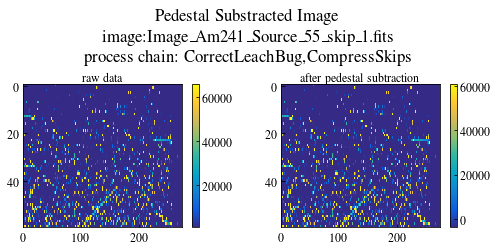

In [12]:
# execute process on raw data
#
ped.execute_process(rdata)

This process create an new attribute on `rdata` object: `image_mean_compressed_pedestal_subtracted`

In [13]:
__process_chain__ = "/CorrectLeachBugProcess/CompressSkipsProcess"

In [14]:
### keeping the image as independent ndarray, to be used later one
image_ps_ex1 = rdata.image_mean_compressed_pedestal_subtracted.copy()

print(" Mean pisel charge before pedestal subtraction: ", rdata.image_mean_compressed.mean())
print(" Mean pixel charge after pedestal subtraction: ", rdata.image_mean_compressed_pedestal_subtracted.mean())
print(" Mean difference: ", rdata.image_mean_compressed.mean()-rdata.image_mean_compressed_pedestal_subtracted.mean())

 Mean pisel charge before pedestal subtraction:  4901.316850881185
 Mean pixel charge after pedestal subtraction:  -6.843809828613744e-13
 Mean difference:  4901.316850881186


The pedestal is just the mean of the full image, see this output and the previous one. 

This methodology to estimate the pedestal (for our type of images) is far from being accurate, but it's allowed! And probably this is never a good option, so to many requirements would have to meet our image: not presence of clusters on the image, uniform pedestal along rows and columns, no sign of noise patterns, ... 

#### Example 2: Pedestal as the median of the full image

Same as before, the use of the full image is never a good idea ... 

Process <PedestalSubtractionProcess> INFO. Equalize the image by substracting the pedestal.
   - using the full image
   - pedestal as the median of a [masked] image (axis full)
   - pedestal estimation is 1101.3871371371372 and its sigma 0.9191691691692085 (in ADUs)
  Pedestral subtracted image recorded as data member image_mean_compressed_pedestal_subtracted of rawdata 




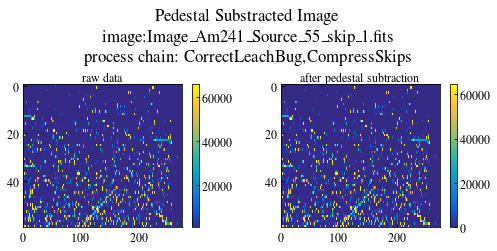

In [15]:
# only for this how to (avoiding overwritting)
rdata.__process_chain__ = __process_chain__

# full image
ped.in_overscan = False
ped.axis = "full"
ped.n_sigma_to_mask = -1
# set method
ped.method = 'median'

ped.execute_process(rdata)

From comparing the output messages from Ex1 and Ex2, we can see that both methods give a very different value for the pedestal!

We run the pedestal subtraction over the same raw data object: $\color{red}{\text{the attribute with the subtracted image has been overwritten!}}$

keeping the subtracted image to be used in the next example:

In [16]:
image_ps_ex2 = rdata.image_mean_compressed_pedestal_subtracted.copy()

#### $\color{red}{\text{Comparing results from Example 1 and Example 2}}$

Where the zero-charge single electrons is located?

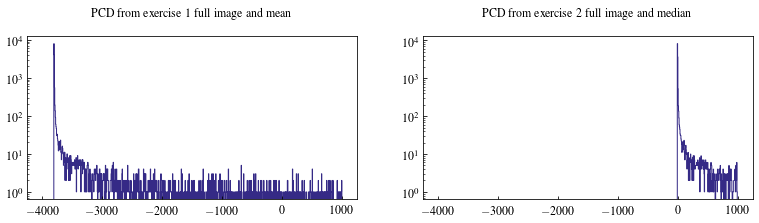

In [17]:
%matplotlib inline
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(13,3))
## example 1
_ = ax1.hist(image_ps_ex1.flatten(), 1000, range=(-4000,1000), histtype='step')
_ = ax1.title.set_text("PCD from exercise 1 full image and mean")
_ = ax1.set_yscale('log')
## example 2
_ = ax2.hist(image_ps_ex2.flatten(), 1000, range=(-4000,1000), histtype='step')
_ = ax2.title.set_text("PCD from exercise 2 full image and median")
_ = ax2.set_yscale('log')

#### Example 3: Pedestal as the median of the overscan


Process <PedestalSubtractionProcess> INFO. Equalize the image by substracting the pedestal.
   - using overscan region
   - pedestal as the median of a [masked] image (axis full)
   - pedestal estimation is 1100.9847347347347 and its sigma 0.48873873873867524 (in ADUs)
  Pedestral subtracted image recorded as data member image_mean_compressed_pedestal_subtracted of rawdata 




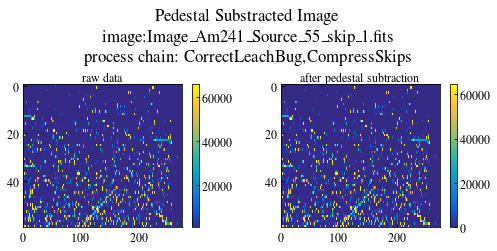

In [18]:
# only for this how to (avoiding overwritting)
rdata.__process_chain__ = __process_chain__

# executing PS process
ped.in_overscan = True
ped.axis = "full"
ped.n_sigma_to_mask = -1
ped.method = 'median'

ped.execute_process(rdata)

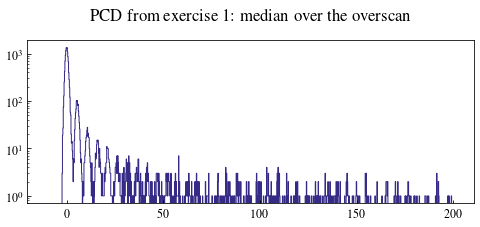

In [19]:
fig, ax = plt.subplots(1,1,figsize=(8,3))

_ = ax.hist(rdata.image_mean_compressed_pedestal_subtracted.flatten(), 1000, range=(-10,200), histtype='step')
_ = ax.title.set_text("PCD from exercise 1: median over the overscan")
_ = ax.set_yscale('log')

#### Example 4: Pedestal as the fitted $\mu$ of the overscan row by row


Process <PedestalSubtractionProcess> INFO. Equalize the image by substracting the pedestal.
   - using overscan region
   - masking image: mask all pixels with qij > median + 10 MAD
   - pedestal as the mu of a the fitted gaussian to the zero-charged peak (axis row)
  Pedestral subtracted image recorded as data member image_mean_compressed_pedestal_subtracted of rawdata 




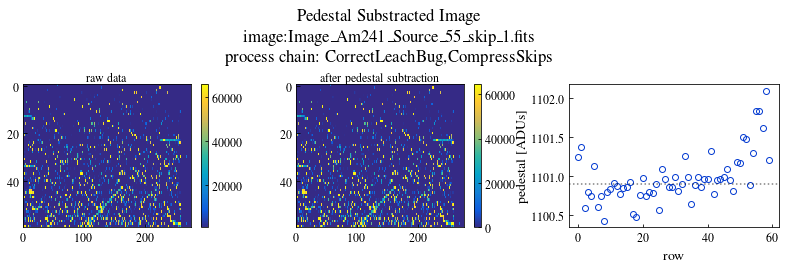

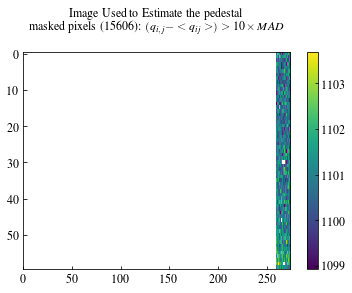

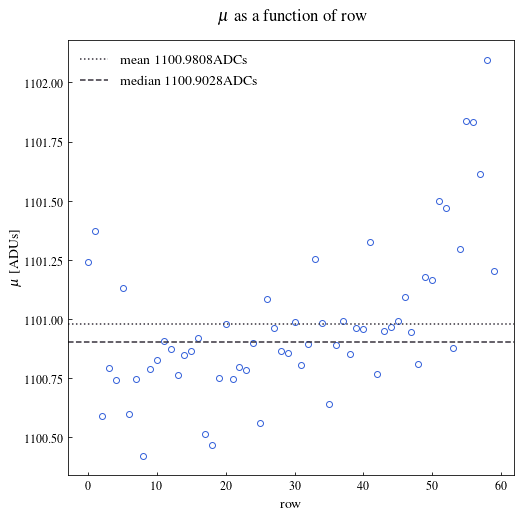

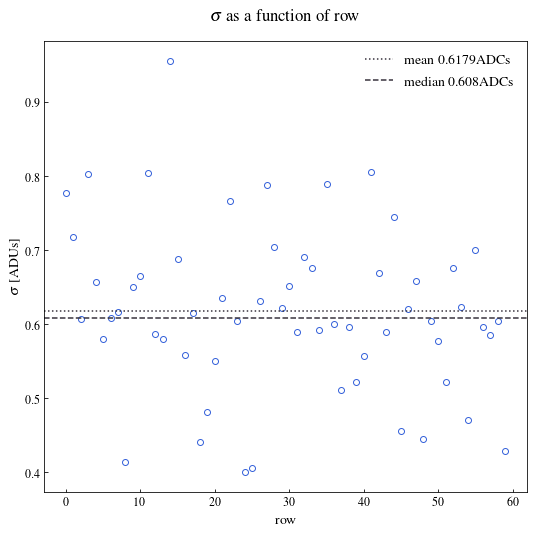

In [20]:
%matplotlib inline
# only for this how to (avoiding overwritting)
rdata.__process_chain__ = __process_chain__

# full image
ped.in_overscan = True
ped.axis = "row"
ped.n_sigma_to_mask = 10
ped.use_mad = True
# set method
ped.method = 'gauss_fit'
ped.execute_process(rdata)

## `pedestal_mu` data member 
#### This data member of `RawData` contains the estimation of the pedestal

In [21]:
print(" There are a pedestal for each row: ", rdata.pedestal_mu[0].shape)
print(" The average pedestal is ", rdata.pedestal_mu[0].mean(), " ADU")
print(" with a dispersion of ", rdata.pedestal_mu[0].std(), " ADU")

 There are a pedestal for each row:  (60, 1)
 The average pedestal is  1100.9808034805255  ADU
 with a dispersion of  0.32472208482501713  ADU


## `pedestal_sigma` data member 
#### This data member of `RawData` contains the dispersion of the pedestal

In [22]:
print(" There are a dispersion of the pedestal for each row: ", rdata.pedestal_sigma[0].shape)
print(" The averaged dispersion is ", rdata.pedestal_sigma[0].mean(), " ADU")
print(" with a dispersion of ", rdata.pedestal_sigma[0].std(), " ADU")

 There are a dispersion of the pedestal for each row:  (60, 1)
 The averaged dispersion is  0.6179264080110766  ADU
 with a dispersion of  0.11127095474926123  ADU


## B. How to from bash: panaSKImg


The main script for analysis is `panaSKImg` also provided by `pysimdamicm`. It is a python3 script to apply a chain of processes over a real data CCD image. Find more information [here](https://ncastell.web.cern.ch/ncastell/pysimdamicm/howtouse_analysis.html).


To $\color{green}{\text{estimate and subtract the pedestal}}$ we can also use `panaSKImg`. We will only need 
* a configuration JSON file and 
* the input image file.

Here is an example of how to run the same as in **Sect. A** (*How to from a Python Interpreter*), but with `panaSKImg`:

```console
    panaSKImg --json <config_file.json> "image_file" --display --verbose -o .
```

`display` and `verbose` will display all plots created along the process. Do not use in case you want to apply the process to more than one image at the same time.

### How to set the parameters of each process?
Two possible ways:

* Using the configuration file
* Or using command lines

It is possible to use both the json file and command lines. $\color{green}{\text{The command lines have preference over those of the json file.}}$

#### by using the JSON file

This has to be done in the configuration file. [Here](./howto_Config.html) you can find information about the full JSON file.


```json
      "PedestalSubtractionProcess":
      {
            "image":"mean_compressed",
            "method":"gauss_fit",
            "in_overscan":true,
            "use_mad":false,
            "axis":"row",
            "n_sigma_win_fit":3,
            "n_sigma_to_mask":10,
      },
```

All these parameters have been explained along this howto.

#### by command line

Almost all parameters has a command line to be pass as an argument of `panaSKImg`. Run

```console
    panaSKImg --help
```

for help on the command lines. Here the output of the help related with `FitDarkCurrentProcess`


```console
*** For Process PedestalSubtractionProcess ************************** :
  --method METHOD       Method to use to compute the pedestal
  --in-overscan         Set to use the full image to estimate the pedestal,
                        instead of only the overscan region
  --axis AXIS           Axis in which the overscan should be computed:
                        row/col/both/none
  --n-sigma-win-fit N_SIGMA_WIN_FIT
                        Number of sigmas to define the spectral window to fit
                        a gaussian to single electron peaks
  --n-sigma-to-mask N_SIGMA_TO_MASK
                        Number of sigmas to define the maximum pixel charge to
                        take into account to estimate the pedestal
  --show-fit            Set to show up several extra plots and information
```


#### `sequence` is mandatory

Remember that the parameter `sequence` of the `process` section of the JSON file must be informed. You can do that using the command line **-s** as follows

```console
    panaSKImg --json <config_file.json> "image_file" -o . -s CompressSkipperProcess,PedestalSubtractionProcess
```

To list all possible process you can just run

```console
    panaSKImg --list-process help
```


## Summary

To estimate the pedestal of images located at **/data/run045** taht follows the file name pattern `Image*Source*fits` just do

```console
    panaSKImg --json <config_file.json> -s CompressSkipperProcess,PedestalSubtractionProcess --func-to-compress mean --in-overscan --axis row --method gauss_fit "/data/run045/Image*Source*fits" -o .
```

where `<config_file.json>` points to the configuration json file.